# PathSnap – full walkthrough: raw data → processed data → final table → model results
Reads Person 1's outputs (`data/processed/`, `results/`). Nothing here trains or changes anything.
Put this notebook in the **repo root** (same level as `src/`, `data/`, `results/`) and run top to bottom.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
from pathlib import Path
from IPython.display import Image, display, HTML

ROOT      = Path(".")                     # repo root
RAW_DIR   = ROOT / "data" / "raw"         # <-- folder with the raw trip files (train + student_test only)
PROC      = ROOT / "data" / "processed"
RESULTS   = ROOT / "results"

TRIP_ID   = "00000001"   # a TRAINING trip for the before/after section
PRED_TRIP = "00000077"   # a STUDENT-TEST trip for the prediction map
PRED_MODEL = "lightgbm_tuned"

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

# Part 1 – BEFORE: the raw files

In [2]:
def find_trip_dir(trip_id):
    hits = list(RAW_DIR.rglob(f"{trip_id}.track"))
    assert hits, f"{trip_id}.track not found under {RAW_DIR}"
    return hits[0].parent

def load_raw(trip_id):
    d = find_trip_dir(trip_id)
    read = lambda ext, names: pd.read_csv(d / f"{trip_id}.{ext}", sep=r"\s+", header=None, names=names)
    return (read("track", ["lon", "lat", "t"]), read("nodes", ["lon", "lat"]),
            read("arcs", ["u", "v"]), read("route", ["arc_id"])["arc_id"].to_numpy())

track, nodes, arcs, route = load_raw(TRIP_ID)
print(f"trip {TRIP_ID} (found in {find_trip_dir(TRIP_ID)})")
print(f"  .track {track.shape}   .nodes {nodes.shape}   .arcs {arcs.shape}   .route {route.shape}")
print(f"  GPS points per route arc: {len(track) / len(route):.1f}  -> .route is a PATH, not per-point labels")
dt = track.t.diff().dropna()
print(f"  time gaps: {dt.value_counts().head(5).to_dict()}  max gap {dt.max():.0f}s")
display(track.head(), arcs.head(), pd.Series(route[:10], name="route (first 10 arc ids)"))

trip 00000001 (found in data/raw/train/00000001)
  .track (1315, 3)   .nodes (88809, 2)   .arcs (165790, 2)   .route (525,)
  GPS points per route arc: 2.5  -> .route is a PATH, not per-point labels
  time gaps: {1.0: 1289, 2.0: 21, 3.0: 2, 16.0: 1, 4.0: 1}  max gap 16s


,lon,lat,t
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


,u,v
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750


0      2641
1     64973
2    133948
3    133949
4    139208
5    133950
6      8970
7    133951
8     64139
9    139211
Name: route (first 10 arc ids), dtype: int64

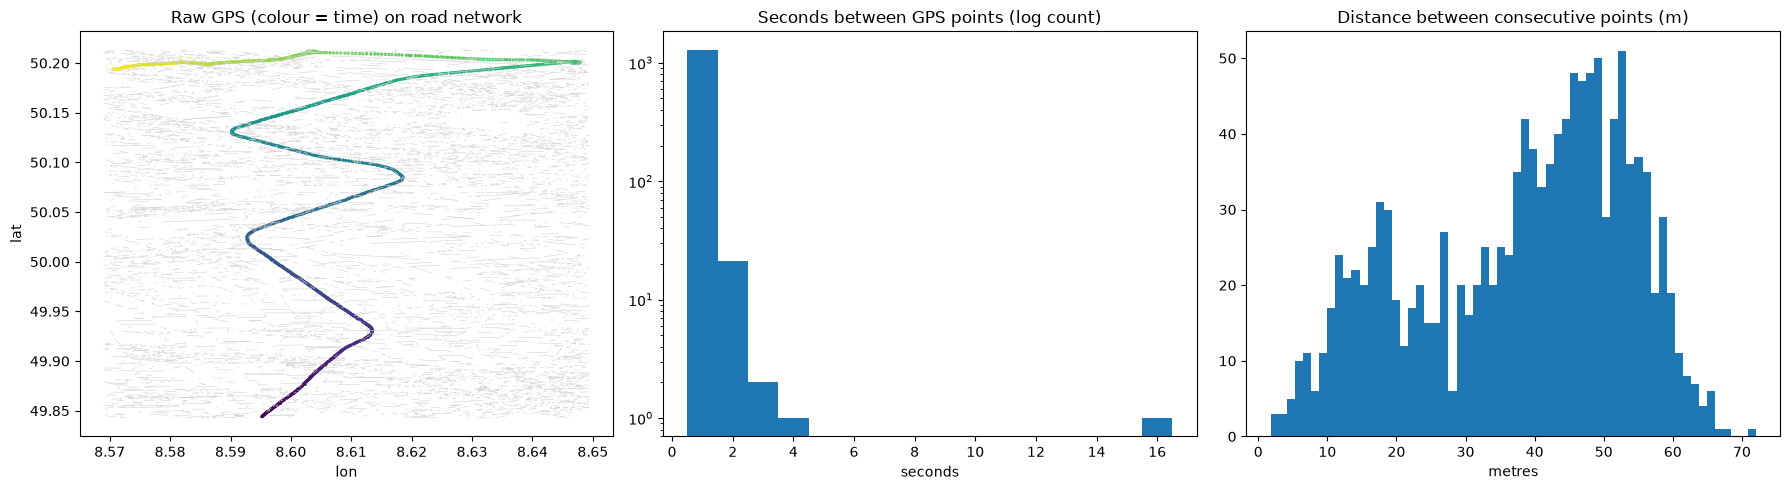

In [3]:
def nearby_arcs(track, nodes, arcs, margin_deg=0.0015):
    """Arcs with an end node within ~150 m of the GPS bounding box (the full network is too big to draw)."""
    box = ((nodes.lon.between(track.lon.min() - margin_deg, track.lon.max() + margin_deg)) &
           (nodes.lat.between(track.lat.min() - margin_deg, track.lat.max() + margin_deg))).to_numpy()
    sel = arcs[box[arcs.u] & box[arcs.v]]
    return sel if len(sel) < 15000 else sel.sample(15000, random_state=0)

near = nearby_arcs(track, nodes, arcs)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for u, v in zip(near.u, near.v):
    ax[0].plot(nodes.lon[[u, v]], nodes.lat[[u, v]], color="lightgrey", lw=0.4)
ax[0].scatter(track.lon, track.lat, c=track.t, s=2, cmap="viridis")
ax[0].set(title="Raw GPS (colour = time) on road network", xlabel="lon", ylabel="lat")
ax[1].hist(dt, bins=np.arange(0.5, min(dt.max(), 30) + 1.5), log=True)
ax[1].set(title="Seconds between GPS points (log count)", xlabel="seconds")
ax[2].hist(np.hypot(np.diff(track.lon) * 111320 * np.cos(np.radians(track.lat.mean())),
                    np.diff(track.lat) * 110540), bins=60)
ax[2].set(title="Distance between consecutive points (m)", xlabel="metres")
plt.tight_layout(); plt.show()

# Part 2 – AFTER processing: one row per GPS point (`points.parquet`)
Each GPS point now has its **true arc** (from the DP route alignment), how far the GPS is from it (`label_dist`),
how many candidates it got, and whether the true arc is among them.

all points: {'student_test': 19160, 'train': 208417}


,trip_id,partition,point_idx,t,lon,lat,true_arc,route_pos,label_dist,n_cands,true_in_cands
0,00000001,train,0,1.0,8.595203,49.844053,64973,1,0.722768,3,True
1,00000001,train,1,2.0,8.595294,49.844441,64973,1,0.277461,2,True
2,00000001,train,2,3.0,8.595352,49.844883,64973,1,1.839765,2,True
3,00000001,train,3,4.0,8.595390,49.845379,64973,1,6.147324,2,True
4,00000001,train,4,5.0,8.595587,49.845750,64973,1,2.652252,2,True
5,00000001,train,5,6.0,8.595555,49.846167,64973,1,5.529618,3,True
6,00000001,train,6,7.0,8.595744,49.846565,133948,2,2.427547,4,True
7,00000001,train,7,8.0,8.595733,49.846931,133949,3,3.467619,4,True
8,00000001,train,8,9.0,8.595878,49.847374,139208,4,0.630973,4,True
9,00000001,train,9,10.0,8.595849,49.847684,139208,4,5.812021,4,True


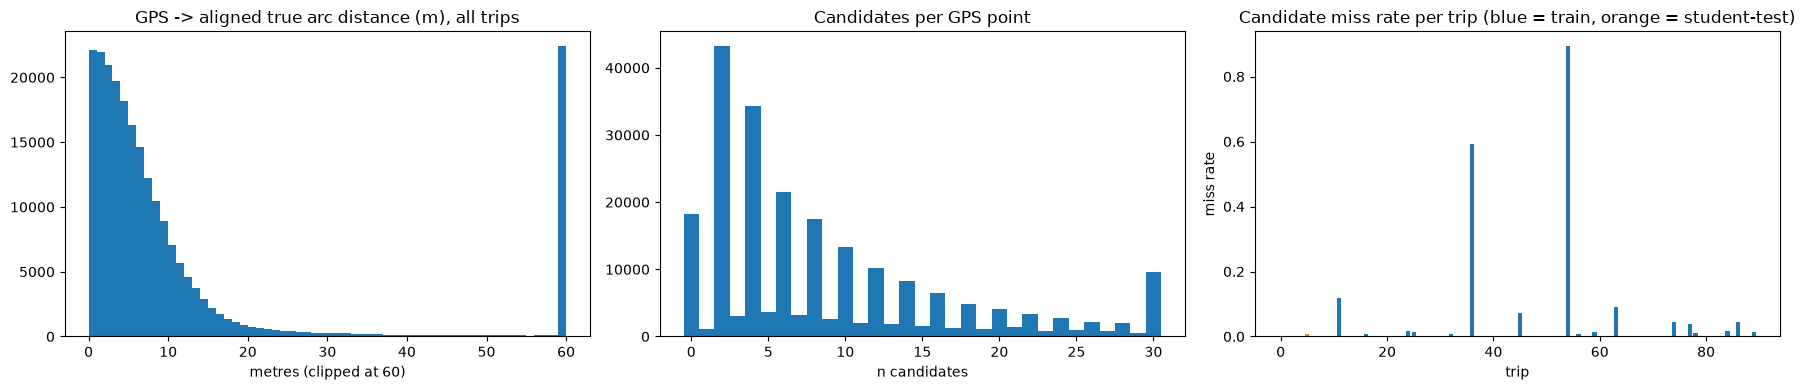

candidate miss rate by partition: {'student_test': 0.0014, 'train': 0.1118}


In [5]:
points = pd.read_parquet(PROC / "points.parquet")
p1 = points[points.trip_id == TRIP_ID].sort_values("point_idx")
print("all points:", points.groupby("partition").size().to_dict())
display(p1.head(10))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(points.label_dist.clip(upper=60), bins=60)
ax[0].set(title="GPS -> aligned true arc distance (m), all trips", xlabel="metres (clipped at 60)")
ax[1].hist(points.n_cands, bins=np.arange(-0.5, points.n_cands.max() + 1.5))
ax[1].set(title="Candidates per GPS point", xlabel="n candidates")
miss = 1 - points.groupby(["partition", "trip_id"]).true_in_cands.mean()
ax[2].bar(range(len(miss)), miss.values, color=["tab:blue" if p == "train" else "tab:orange" for p, _ in miss.index])
ax[2].set(title="Candidate miss rate per trip (blue = train, orange = student-test)", xlabel="trip", ylabel="miss rate")
plt.tight_layout(); plt.show()
print("candidate miss rate by partition:", (1 - points.groupby("partition").true_in_cands.mean()).round(4).to_dict())

# Part 3 – (`features.parquet`)
One row per **(GPS point, candidate arc)**, 17 features, `label` = 1 if the candidate is the point's true arc.

In [7]:
cfg = json.loads((PROC / "dataset_config.json").read_text())
FEATURES = cfg.get("features") or cfg.get("FEATURES")
print("dataset config:", {k: v for k, v in cfg.items() if k not in ("features", "FEATURES")})
print("features:", FEATURES)

feats = pd.read_parquet(PROC / "features.parquet")
summary = feats.groupby("partition").agg(trips=("trip_id", "nunique"), rows=("label", "size"), positive_rate=("label", "mean"))
display(summary)
print("example: all candidates of one GPS point")
ex = feats[(feats.trip_id == TRIP_ID)]
display(ex[ex.point_idx == ex.point_idx.iloc[len(ex) // 2]][["trip_id", "point_idx", "arc_id", *FEATURES, "label"]])
display(feats[FEATURES].describe().T.round(3))

dataset config: {'R_m': 50.0, 'K': 30, 'n_folds': 5, 'seed': 42, 'label_method': 'dp_monotone_alignment', 'pos_rate': 0.10356595389507557, 'build_seconds': 26.948253870010376}
features: ['dist_m', 'dist_rank', 'dist_gap_min', 'n_cands', 'heading_diff', 'heading_reliable', 'speed_ms', 'turn_rate', 'arc_len_m', 'along_t', 'dt_prev', 'dist_prev_pt', 'dist_next_pt', 'dist_win5', 'heading_diff_win5', 'node_deg_sum', 'is_two_way']


,trips,rows,positive_rate
partition,,,
student_test,10,200052,0.095640
train,80,1772015,0.104461


example: all candidates of one GPS point


,trip_id,point_idx,arc_id,dist_m,dist_rank,dist_gap_min,n_cands,heading_diff,heading_reliable,speed_ms,turn_rate,arc_len_m,along_t,dt_prev,dist_prev_pt,dist_next_pt,dist_win5,heading_diff_win5,node_deg_sum,is_two_way,label
7648,00000001,866,5864,20.919443,5.0,17.560320,10,178.601044,1,41.665482,5.61753,1085.680908,0.476882,1.0,19.076651,21.111099,18.602339,176.063416,4,0,0
7649,00000001,866,22062,17.822260,1.0,14.463138,10,60.137760,1,41.665482,5.61753,54.601471,0.927346,1.0,18.868811,55.612473,48.508942,57.600136,8,1,0
7650,00000001,866,22063,17.822260,1.0,14.463138,10,119.862236,1,41.665482,5.61753,54.601471,0.072654,1.0,18.868811,55.612473,48.508942,122.399864,8,1,0
7651,00000001,866,22064,18.258432,3.0,14.899310,10,67.911568,1,41.665482,5.61753,12.128010,0.000000,1.0,32.088360,55.008789,55.322178,65.373940,10,1,0
7652,00000001,866,22065,25.184774,8.0,21.825651,10,112.377335,1,41.665482,5.61753,144.521484,1.000000,1.0,41.696629,55.150860,60.107113,114.914963,12,1,0
7653,00000001,866,117932,18.258432,3.0,14.899310,10,112.088432,1,41.665482,5.61753,12.128010,1.000000,1.0,32.088360,55.008789,55.322178,114.626060,10,1,0
7654,00000001,866,117933,25.184774,8.0,21.825651,10,67.622665,1,41.665482,5.61753,144.521484,0.000000,1.0,41.696629,55.150860,60.107113,65.085037,12,1,0
7655,00000001,866,117934,22.916027,6.0,19.556904,10,3.762757,1,41.665482,5.61753,79.314095,0.131710,1.0,41.696629,21.051207,38.719219,6.300381,10,1,0
7656,00000001,866,117935,22.916027,6.0,19.556904,10,176.237244,1,41.665482,5.61753,79.314095,0.868290,1.0,41.696629,21.051207,38.719219,173.699615,10,1,0
7657,00000001,866,129491,3.359123,0.0,0.000000,10,0.093625,1,41.665482,5.61753,185.263062,0.606157,1.0,2.490334,2.626501,4.586264,2.631249,4,0,1


,count,mean,std,min,25%,50%,75%,max
dist_m,1972067.0,24.294,14.877,0.000,10.672,24.177,37.431,50.000
dist_rank,1972067.0,6.979,6.908,0.000,2.000,4.000,10.000,29.000
dist_gap_min,1972067.0,18.881,14.982,0.000,3.558,18.202,31.837,49.965
n_cands,1972067.0,16.046,9.050,1.000,8.000,15.000,24.000,30.000
heading_diff,1972067.0,88.133,61.759,0.000,25.573,87.075,150.651,180.000
heading_reliable,1972067.0,0.982,0.131,0.000,1.000,1.000,1.000,1.000
speed_ms,1972067.0,10.687,8.786,0.000,4.284,8.215,14.713,135.414
turn_rate,1972067.0,39.617,45.119,0.000,7.556,20.468,55.021,180.000
arc_len_m,1972067.0,84.351,189.979,0.070,15.195,34.041,79.719,4671.058
along_t,1972067.0,0.498,0.445,-0.000,0.000,0.494,1.000,1.000


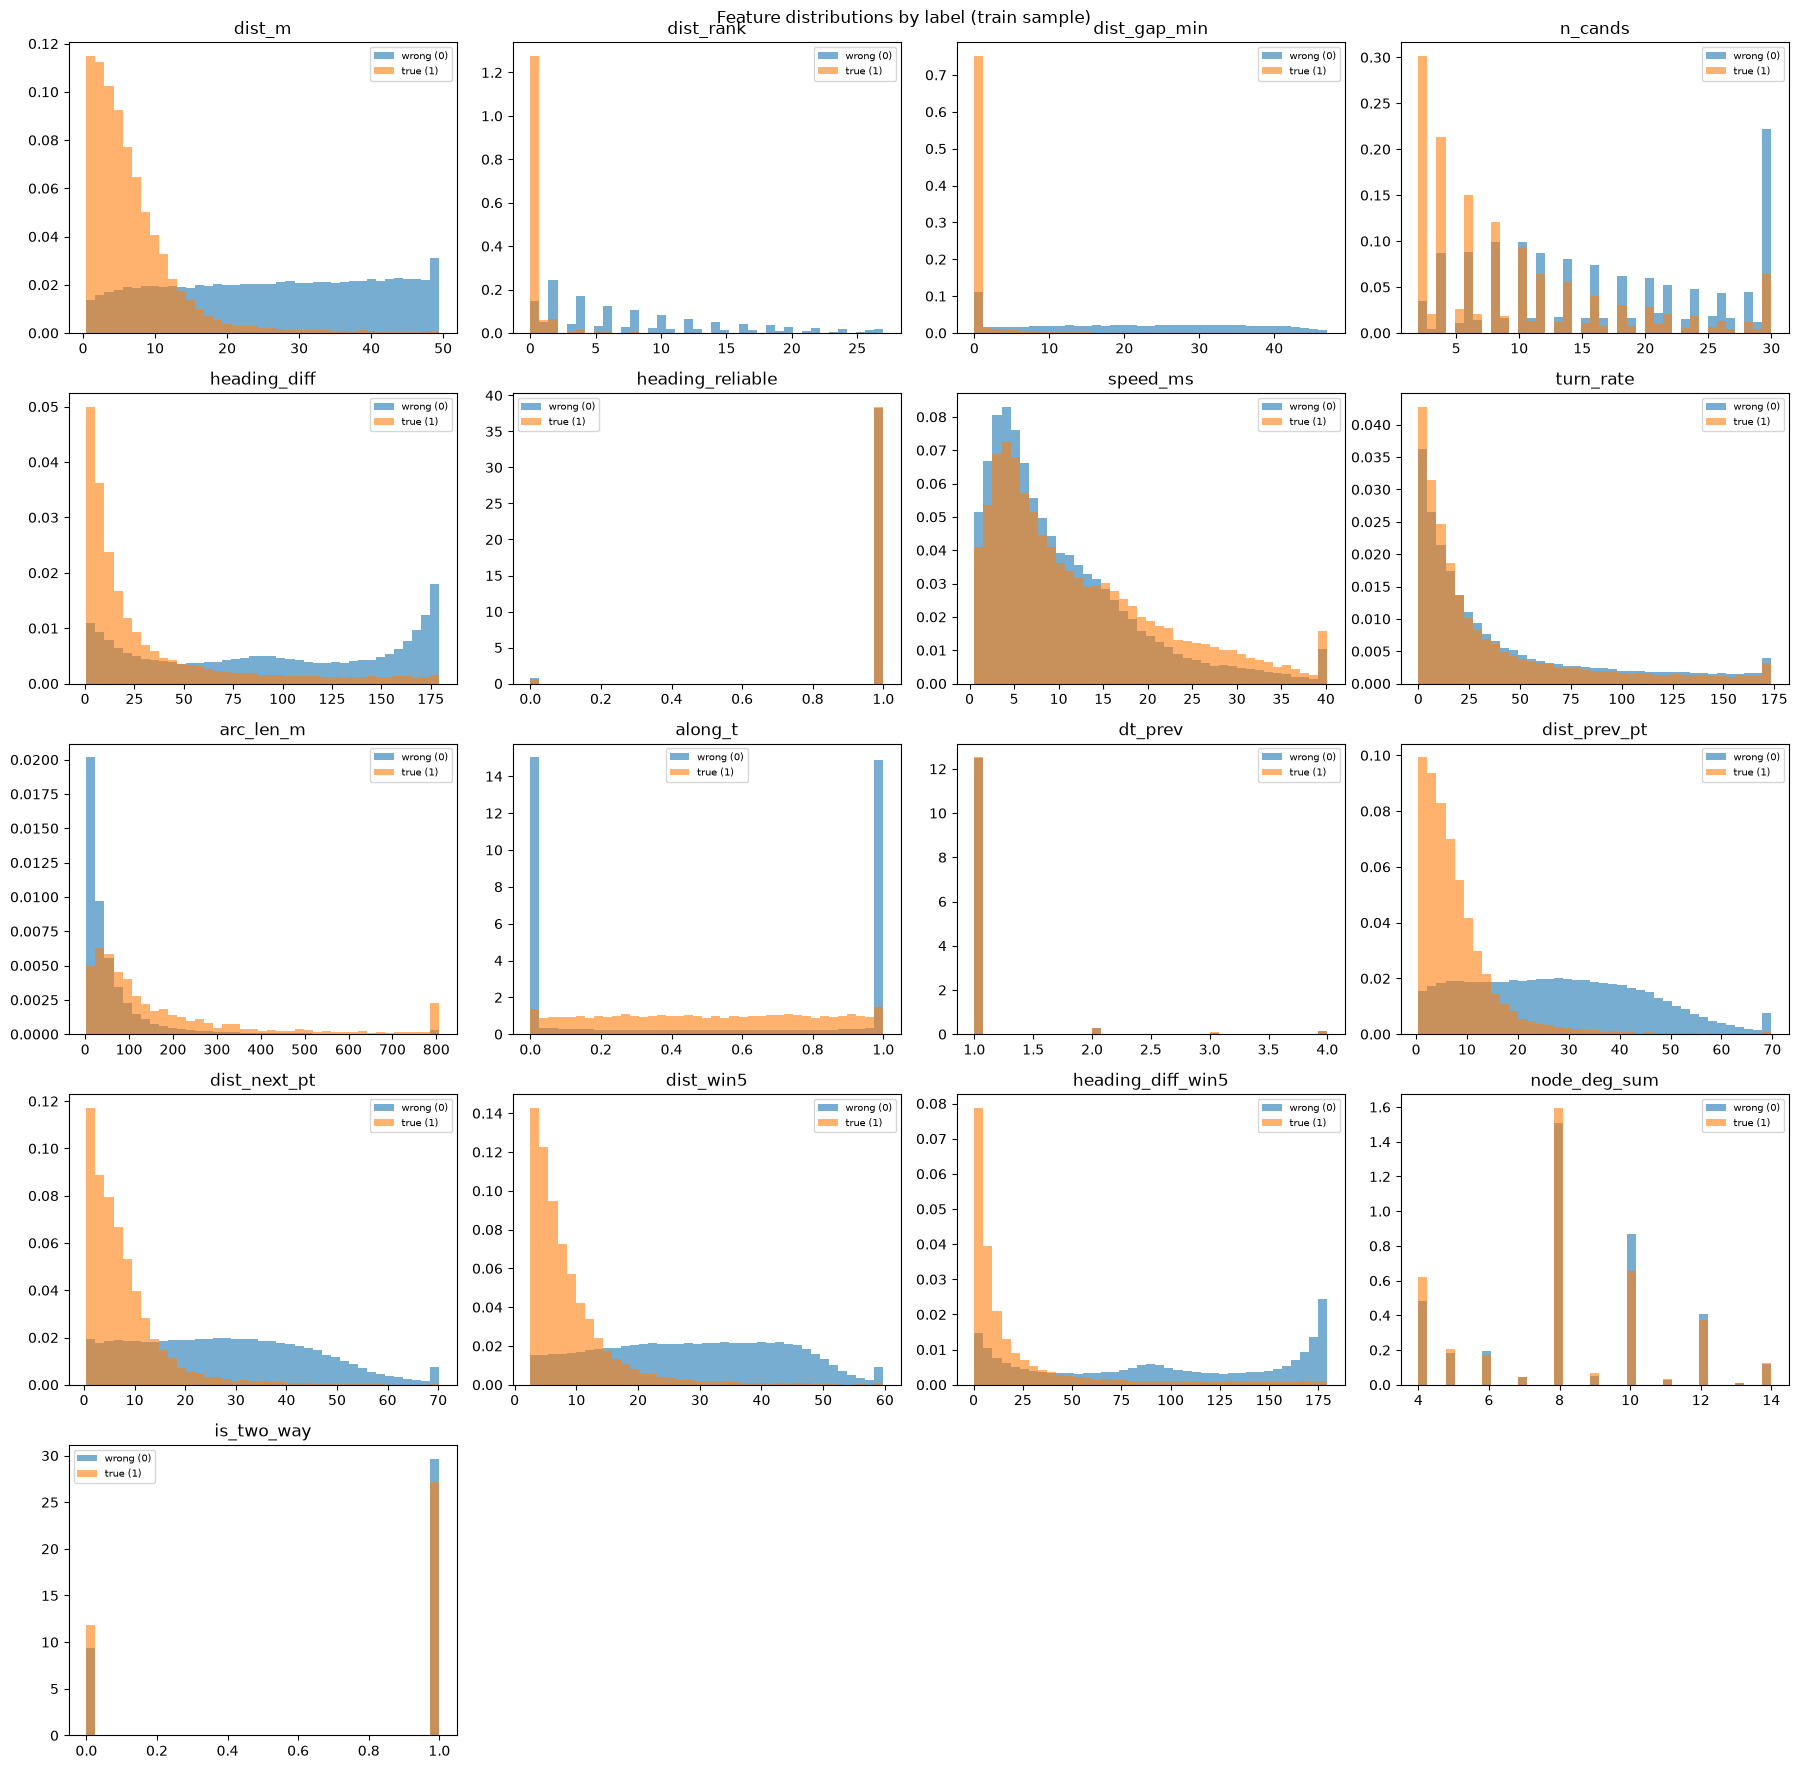

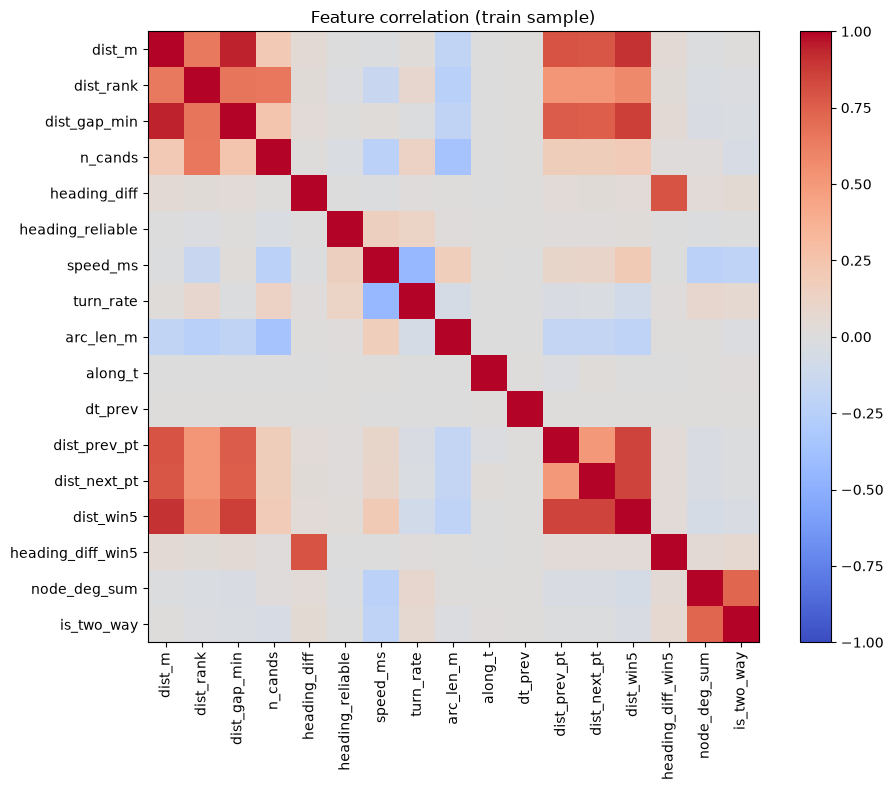

In [8]:
# Feature distributions: true road (label 1) vs wrong road (label 0), training rows only
train_rows = feats[feats.partition == "train"]
sample = train_rows.sample(min(300_000, len(train_rows)), random_state=0)
n = len(FEATURES); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(18, 3.6 * rows))
for ax, f in zip(axes.ravel(), FEATURES):
    lo, hi = sample[f].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi if hi > lo else lo + 1, 40)
    ax.hist(sample.loc[sample.label == 0, f].clip(lo, hi), bins=bins, alpha=0.6, density=True, label="wrong (0)")
    ax.hist(sample.loc[sample.label == 1, f].clip(lo, hi), bins=bins, alpha=0.6, density=True, label="true (1)")
    ax.set_title(f); ax.legend(fontsize=7)
for ax in axes.ravel()[n:]: ax.axis("off")
plt.suptitle("Feature distributions by label (train sample)"); plt.tight_layout(); plt.show()

corr = sample[FEATURES].corr()
plt.figure(figsize=(10, 8)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(n), FEATURES, rotation=90); plt.yticks(range(n), FEATURES)
plt.title("Feature correlation (train sample)"); plt.tight_layout(); plt.show()

# Part 4 – MODEL RESULTS (`results/results.csv`)

,model,family,config,features,train_frac,author,cv_macro_f1_mean,cv_macro_f1_std,cv_top1_mean,cv_top1_std,cv_top1_covered_mean,cv_log_loss_mean,train_time_s,train_macro_f1,test_top1,test_top1_covered,test_top1_trip_mean,test_macro_f1,test_precision,test_recall,test_accuracy,test_log_loss,test_route_continuity,inference_time_s,inference_ms_per_1k_points,timestamp
0,nearest_arc,Heuristic (non-learned reference),"{""rule"": ""pick candidate with smallest perpend...",17,1.0,person1,0.750814,0.009910,0.508679,0.063188,0.571622,0.295376,0.078702,0.752669,0.544154,0.544922,0.564131,0.747493,0.511297,0.587833,0.906844,0.257341,0.820104,0.002701,0.140984,2026-11-18 05:09:34
1,logreg,Linear / probabilistic,"{""scaler"": ""StandardScaler"", ""C"": 1.0, ""penalt...",17,1.0,person1,0.901342,0.013911,0.781410,0.119377,0.867659,0.110121,4.274082,0.905254,0.869468,0.870695,0.883997,0.911816,0.844829,0.836042,0.969633,0.086872,0.931123,0.017081,0.891494,2026-11-18 05:09:57
2,gaussian_nb,Linear / probabilistic (generative),"{""transform"": ""QuantileTransformer(normal)"", ""...",17,1.0,person1,0.805473,0.010384,0.747680,0.120050,0.829546,0.724737,4.138236,0.805436,0.838779,0.839962,0.843084,0.806637,0.524814,0.902002,0.912518,0.623419,0.896084,0.355479,18.553171,2026-11-18 05:10:33
3,lightgbm,Boosting (gradient boosted trees),"{""n_estimators"": 400, ""learning_rate"": 0.05, ""...",17,1.0,person1,0.926153,0.015772,0.791816,0.119093,0.879562,0.072479,33.449572,0.950659,0.881367,0.882611,0.896927,0.931126,0.888955,0.861914,0.976496,0.057974,0.939008,2.473797,129.112594,2026-11-18 05:13:57
4,xgboost,Boosting (gradient boosted trees),"{""n_estimators"": 400, ""learning_rate"": 0.05, ""...",17,1.0,person1,0.925558,0.015513,0.791787,0.119438,0.879433,0.072928,33.035398,0.948083,0.883142,0.884388,0.899219,0.932756,0.891666,0.865102,0.977046,0.057189,0.940574,0.591596,30.876597,2026-11-18 05:16:56
5,random_forest,Ensemble (bagging),"{""n_estimators"": 100, ""max_depth"": null, ""min_...",17,1.0,person1,0.923511,0.015771,0.787530,0.118877,0.874784,0.078673,97.986197,0.942117,0.877557,0.878796,0.893657,0.929655,0.897700,0.848482,0.976261,0.060208,0.934360,0.841865,43.938672,2026-11-18 05:25:12
6,lightgbm_tuned,Boosting (gradient boosted trees) – Optuna tuned,"{""n_estimators"": 450, ""learning_rate"": 0.03936...",17,1.0,person1,0.926667,0.015436,0.792074,0.118777,0.879910,0.072140,42.590361,0.950663,0.883194,0.884440,0.900820,0.932270,0.893453,0.861653,0.976941,0.057459,0.940157,3.480109,181.634104,2026-11-18 06:17:23


plotting columns: {'CV macro F1': 'cv_macro_f1_mean', 'Student-test Top-1': 'test_top1', 'Student-test macro F1': 'test_macro_f1', 'Log loss': 'cv_log_loss_mean', 'Inference (ms/1k pts)': 'inference_time_s'}


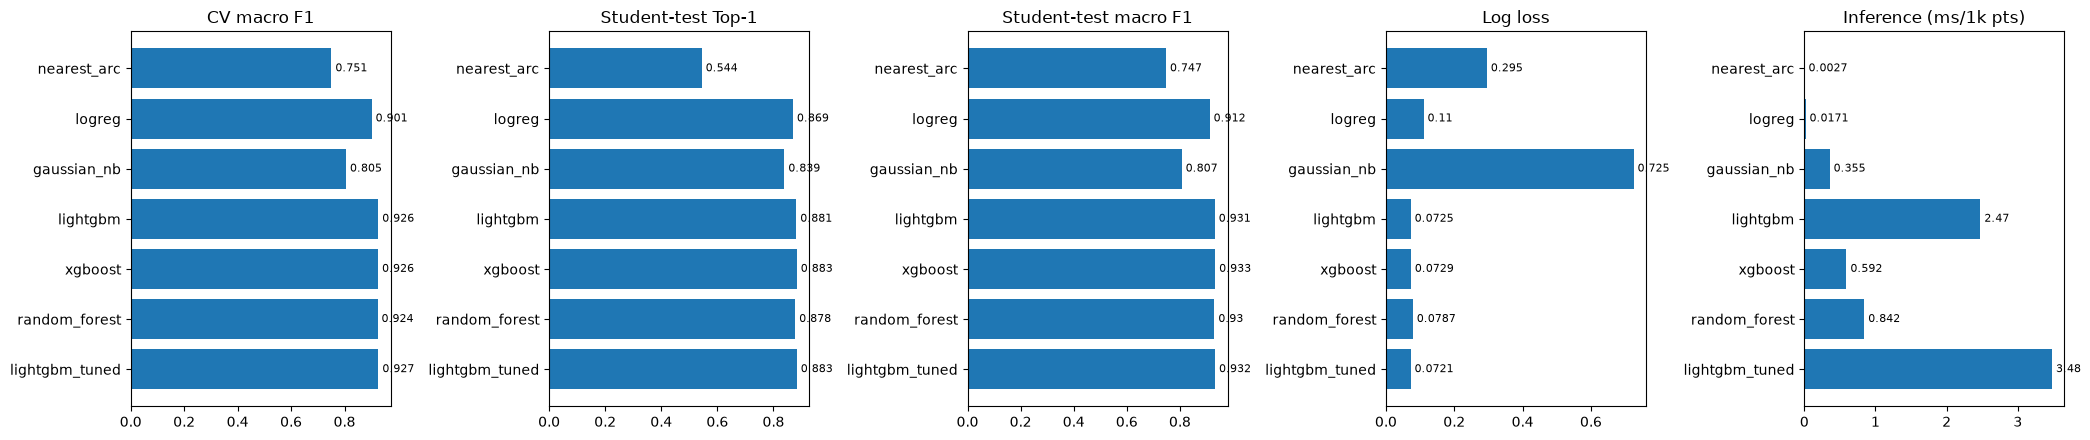

In [9]:
res = pd.read_csv(RESULTS / "results.csv")
display(res)

name_col = next(c for c in res.columns if c.lower() in ("model", "name"))
def col(*keys):
    """find a results column whose name contains all keys (case-insensitive)"""
    for c in res.columns:
        if all(k.lower() in c.lower() for k in keys): return c
metrics = {"CV macro F1": col("cv", "f1"), "Student-test Top-1": col("test", "top"),
           "Student-test macro F1": col("test", "f1"), "Log loss": col("log"),
           "Inference (ms/1k pts)": col("inference")}
metrics = {k: v for k, v in metrics.items() if v}
print("plotting columns:", metrics)

fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 4.5))
for ax, (title, c) in zip(np.atleast_1d(axes), metrics.items()):
    vals = pd.to_numeric(res[c].astype(str).str.split("±").str[0].str.strip(), errors="coerce")
    ax.barh(res[name_col], vals, color="tab:blue")
    ax.set_title(title); ax.invert_yaxis()
    for y, v in enumerate(vals):
        if pd.notna(v): ax.text(v, y, f" {v:.3g}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

confusion_matrices.png


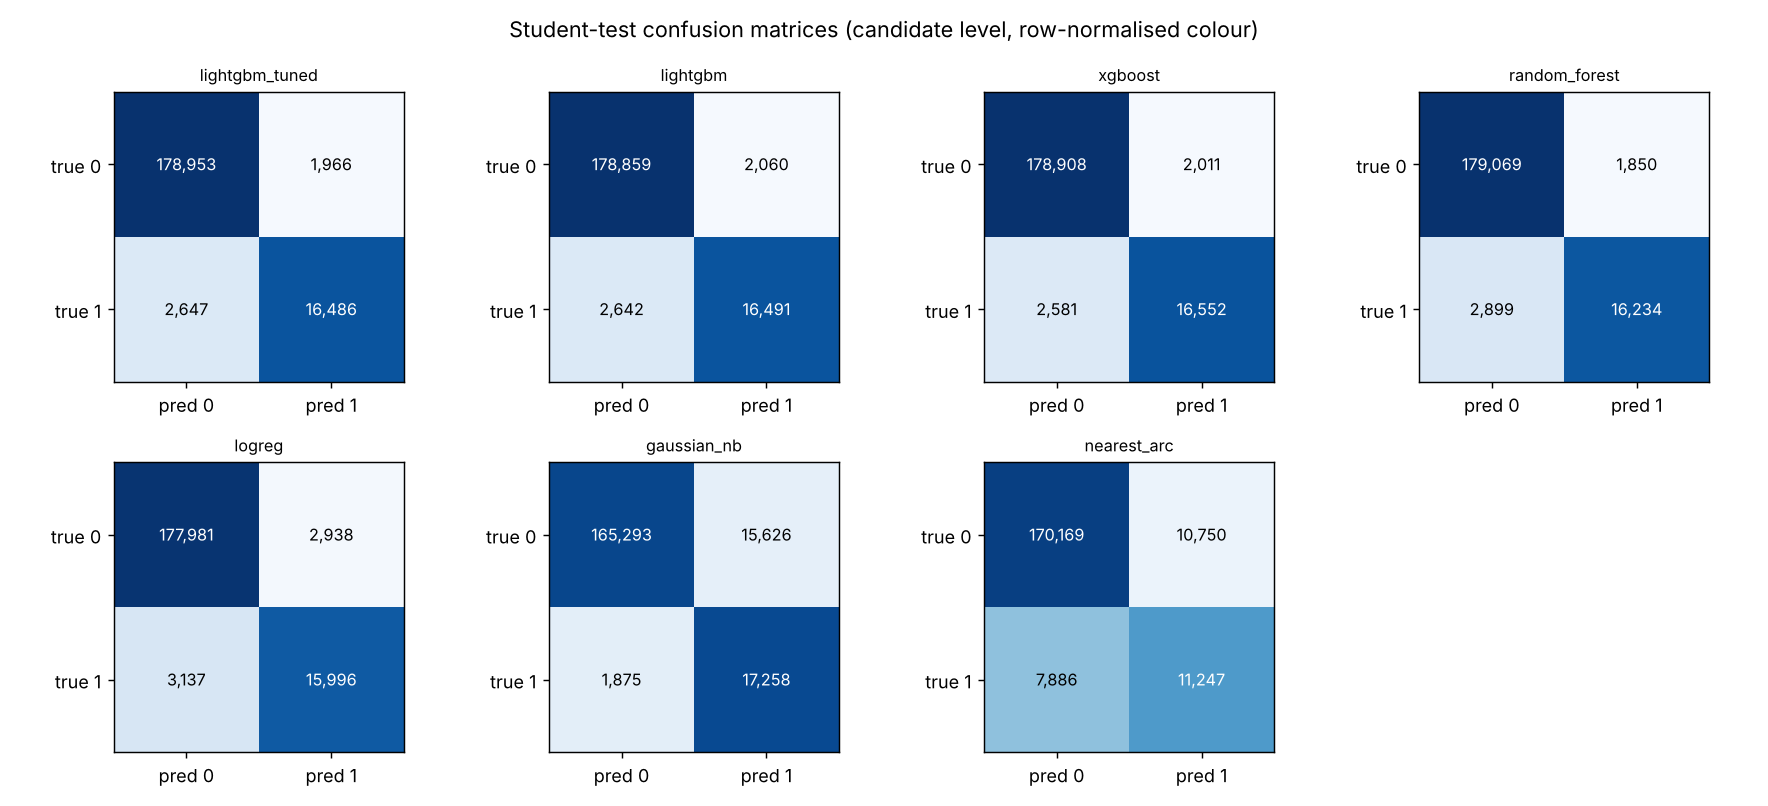

cv_folds.png


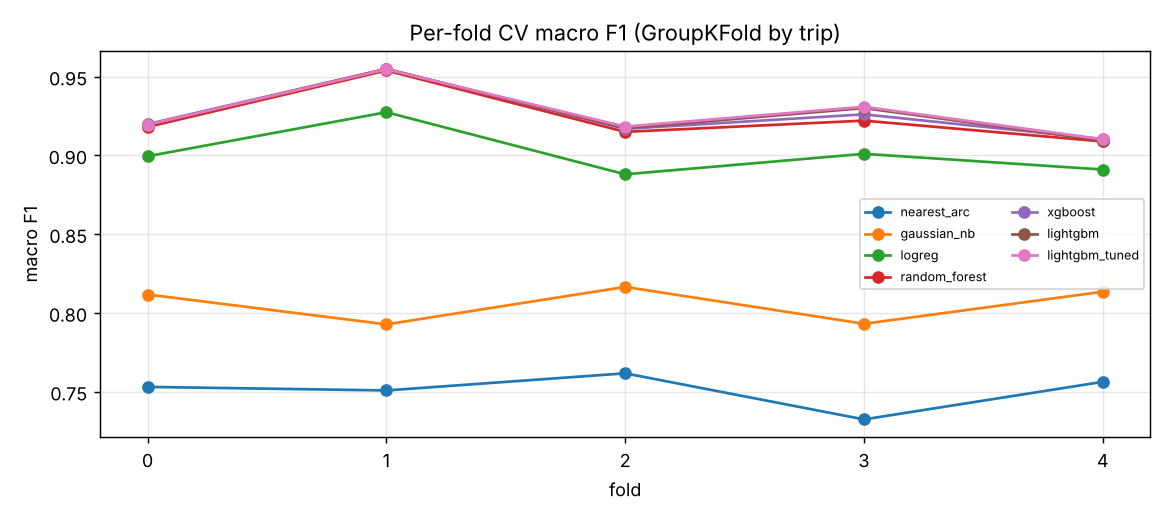

feature_importance_lightgbm.png


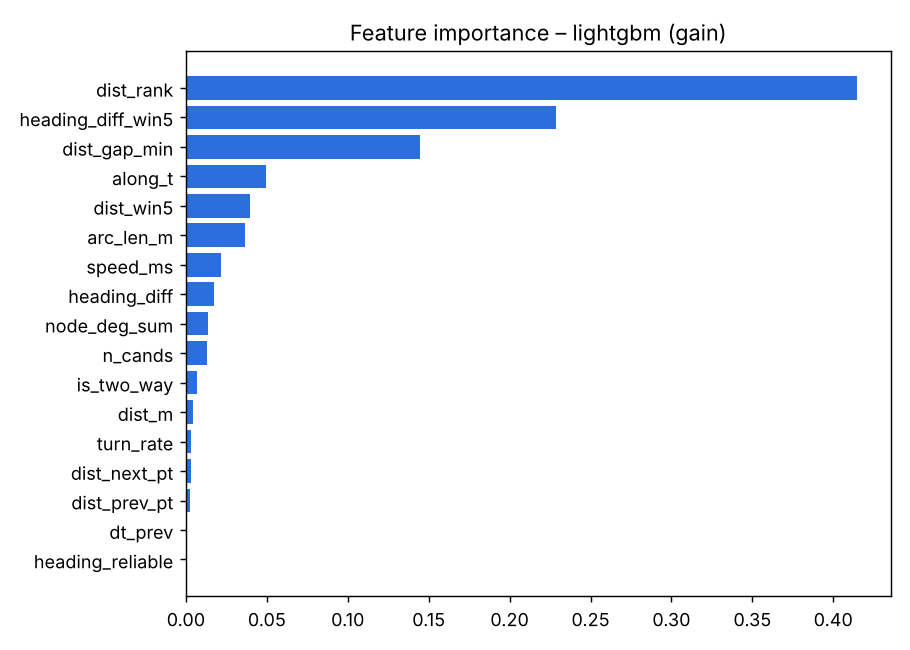

feature_importance_lightgbm_tuned.png


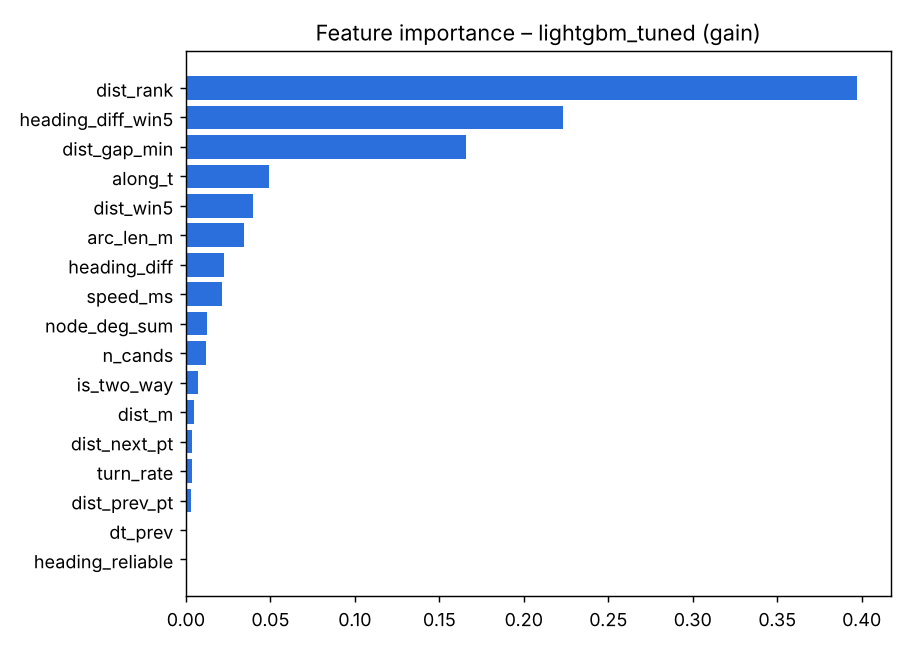

feature_importance_random_forest.png


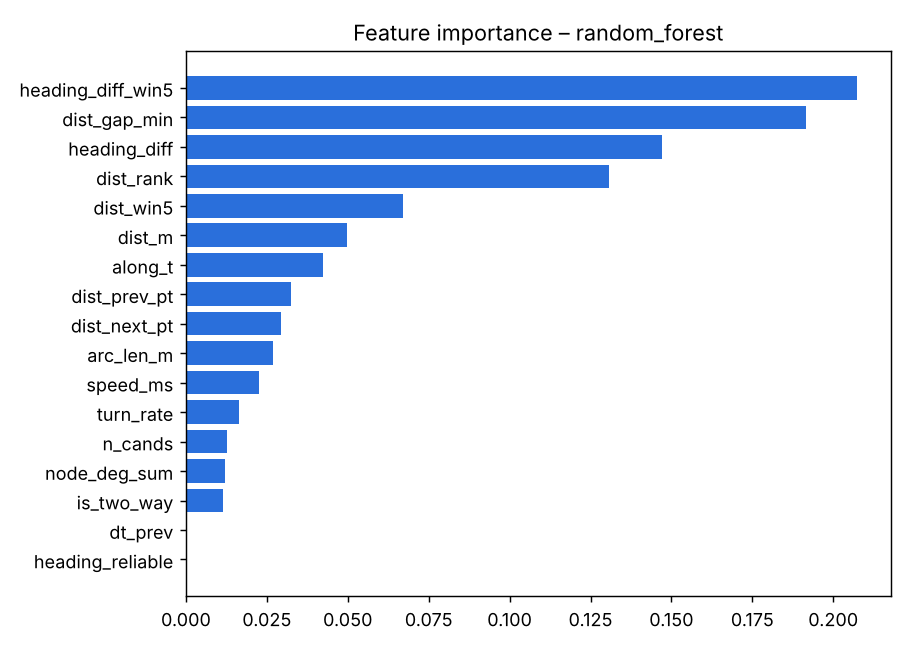

feature_importance_xgboost.png


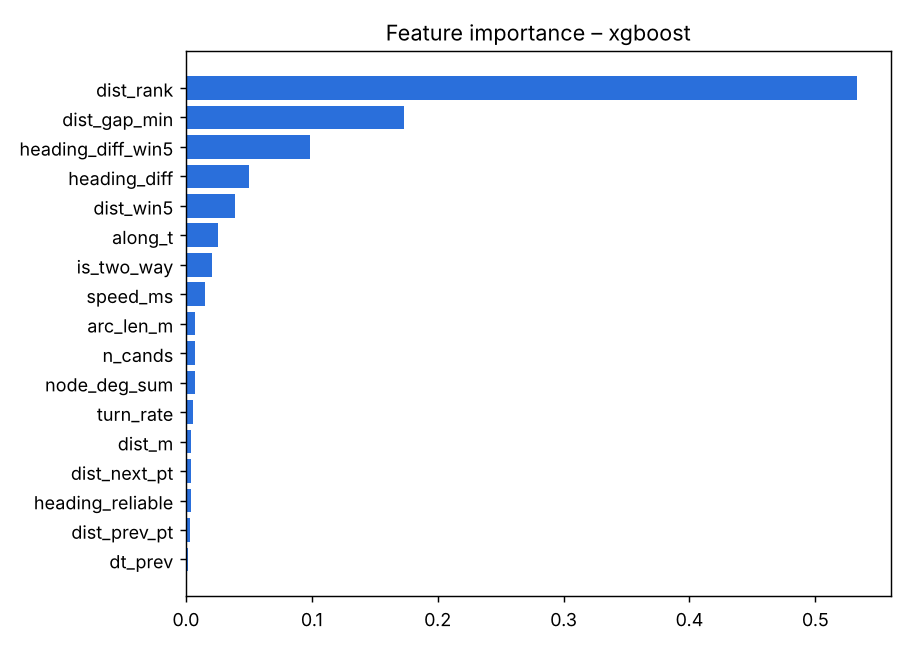

logloss_inference.png


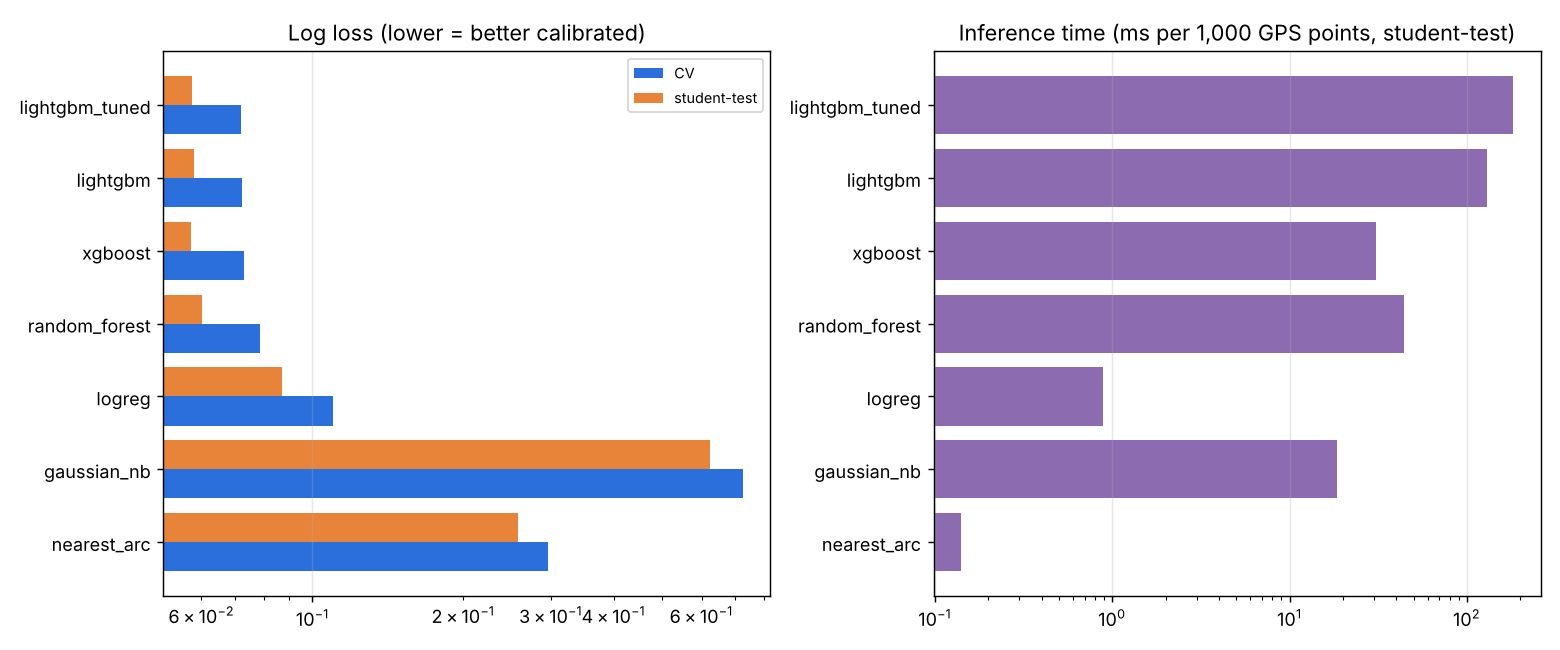

macro_f1_comparison.png


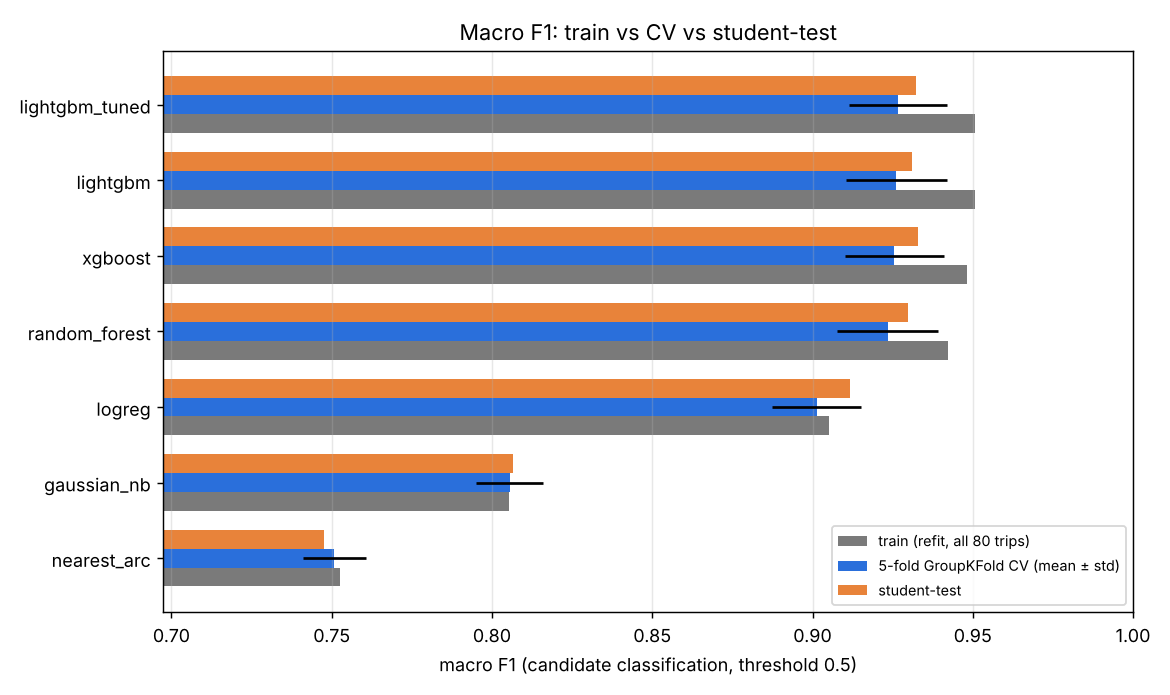

top1_comparison.png


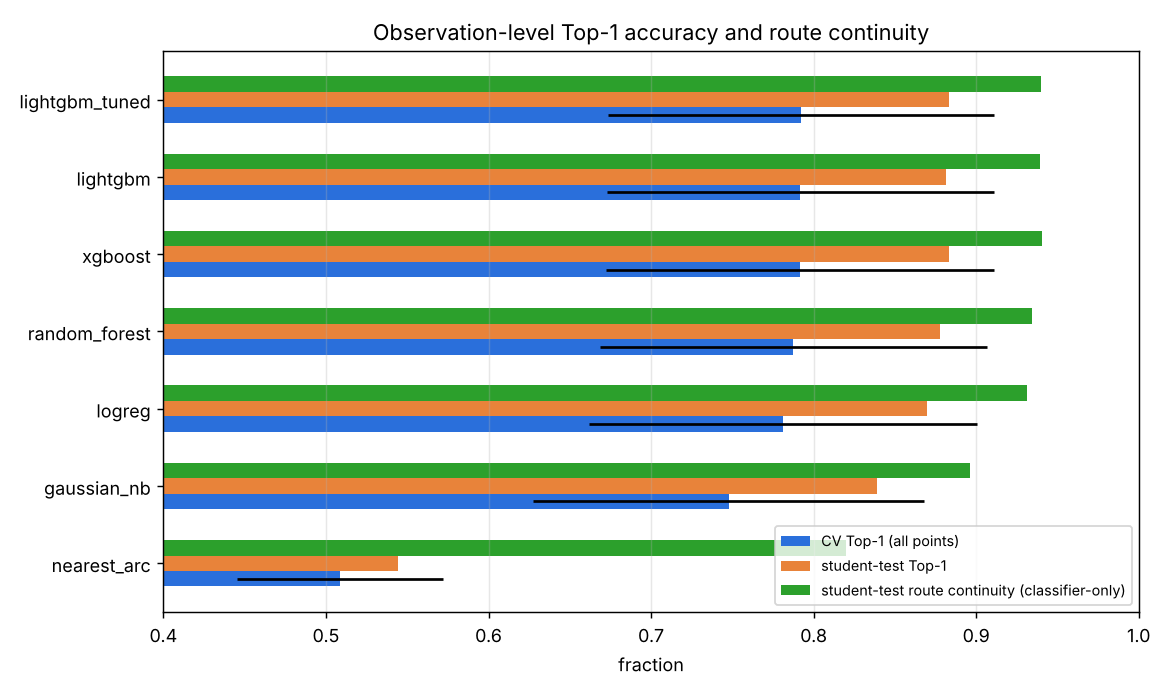

lightgbm_history.png


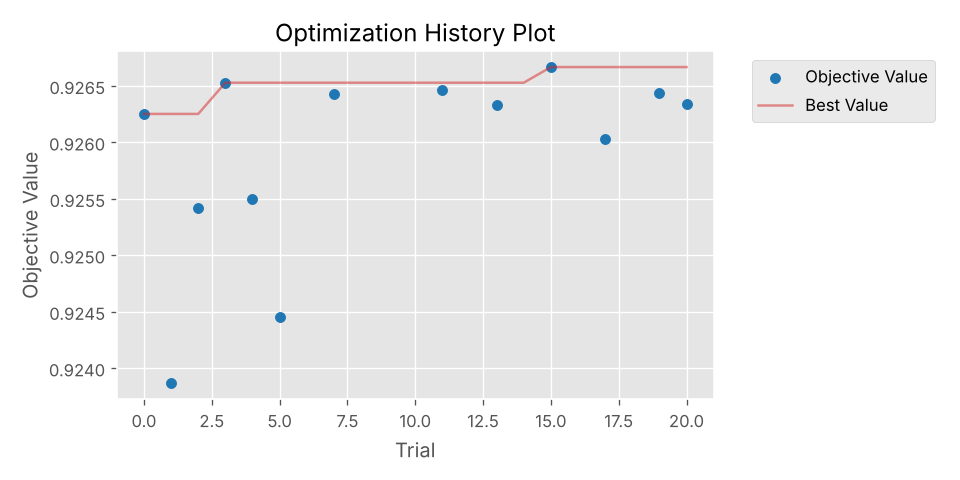

lightgbm_param_importance.png


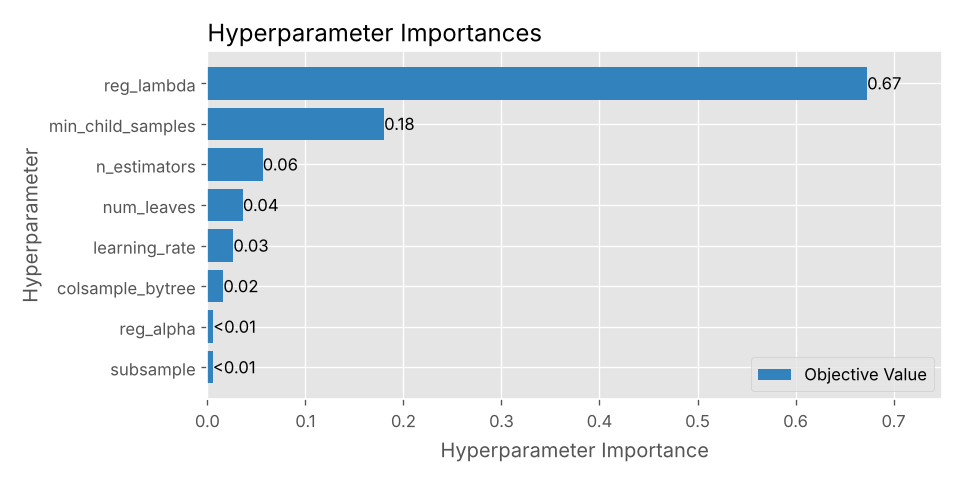

,Unnamed: 0,lightgbm,lightgbm_tuned,delta
0,cv_macro_f1_mean,0.926153,0.926667,0.000514
1,cv_macro_f1_std,0.015772,0.015436,-0.000336
2,cv_top1_mean,0.791816,0.792074,0.000257
3,cv_log_loss_mean,0.072479,0.072140,-0.000339
4,train_macro_f1,0.950659,0.950663,0.000004
5,test_top1,0.881367,0.883194,0.001827
6,test_macro_f1,0.931126,0.932270,0.001144
7,test_precision,0.888955,0.893453,0.004499
8,test_recall,0.861914,0.861653,-0.000261
9,test_log_loss,0.057974,0.057459,-0.000516


In [10]:
# Person 1's saved plots
for f in sorted((RESULTS / "plots").glob("*.png")):
    print(f.name); display(Image(filename=str(f), width=900))
for f in sorted((RESULTS / "optuna").glob("*.png")):
    print(f.name); display(Image(filename=str(f), width=700))
tvu = RESULTS / "optuna" / "tuned_vs_untuned.csv"
if tvu.exists(): display(pd.read_csv(tvu))